In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

/tmp/ipykernel_22628/687462750.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [2]:
DATA_PATH = '../../data'
MERGEGEN_RESULTS = '../../mergeGen/RESULTS'
SBCR_RESULTS = '../../sbcr'
ANALYSIS_PATH = '../../analysis'
INTERMEDIARY_RESULTS = f"{ANALYSIS_PATH}/intermediary_data"

MERGEGEN_DATASET2_JAVA = f"{MERGEGEN_RESULTS}/mergeGen_dataset2_Java_model_dataset2_Java_similarities.csv"
SBCR_DATASET2 = f"{SBCR_RESULTS}/rq1_Java/RESULTS/results_evaluate_dataset2_Java_combination_rq1_Java_seed-3022024.xlsx"

DATASET2_COMPLETE = f"{DATA_PATH}/dataset2_complete.json" 
DATASET2_JAVA_TESTING = f"{DATA_PATH}/dataset2_Java_testing.json"
DATASET2_JAVA_METADATA = f"{DATA_PATH}/dataset2_Java_metadata.json"
DATASET2_STATS = f"{DATA_PATH}/dataset2_Java_complete_stats.csv"

MERGEGEN_BETTER = f"{INTERMEDIARY_RESULTS}/rq4_dataset2_Java_qualitative_list_MergegenBetter.csv"
SBCR_BETTER = f"{INTERMEDIARY_RESULTS}/rq4_dataset2_Java_qualitative_list_SBCRBetter.csv"

In [3]:
df_complete_ds2 = pd.read_json(DATASET2_COMPLETE)

In [4]:
df_test_ds2 = pd.read_json(DATASET2_JAVA_TESTING)
df_test_ds2

,all_raw_base,all_raw_a,all_raw_b,all_raw_res,merge_id,chunk_number
0,,this.config.setFilterBranchName(filter...,\n this.config.getContent().setShowTrig...,this.config.setFilterBranchName(filter...,201013,5
1,if (!updatedSubscribers.add(s.getSup...,if (!updatedSubscribers.add(s.getSup...,\n try {\n if (!updatedSub...,try {\n if (!updatedSubsc...,7891,2
2,"volumeData.add(new Pair<String, Ob...",volResponse.setDiskOfferingId(volu...,"\n volumeData.add(new Pair<String, ...",volResponse.setDiskOfferingId(volu...,218666,3
3,,import net.minecraft.pathfinding.PathNavigator;\n,\nimport net.minecraft.potion.EffectInstance;\...,import net.minecraft.pathfinding.PathNavigator...,272664,1
4,\n,,\n \n public JSONObject sanitizeJson(Htt...,\n public JSONObject sanitizeJson(HttpS...,55721,2
...,...,...,...,...,...,...
6570,processor = MessageMappingProcesso...,processor = MessageMappingProcesso...,\n processor = MessageMappingProces...,processor = MessageMappingProcesso...,177280,2
6571,\t\t\t\t// Meta.g:1:360: T_TERM\n,\t\t\t\t// Meta.g:1:326: T_UDF\n,\n\t\t\t\t// Meta.g:1:341: T_CLUSTERING\n,,101077,97
6572,"Position prev = new Position(0, 0, 0, ...","Position prev = new Position(0, 0, 0, ...",\n EntityPlayer player = runner.outside...,EntityPlayer player = runner.outside.a...,15144,1
6573,* @return true if the workflow has comple...,* @return true if the workflow has comple...,\n * @return true if the workflow is in te...,* @return true if the workflow has comple...,39379,16


In [5]:
df_mergegen_ds2 = pd.read_csv(MERGEGEN_DATASET2_JAVA)
data = []
for index, row in df_mergegen_ds2.iterrows():
    chunk = df_complete_ds2.iloc[row['chunk_index']]
    chunk_id = f"{chunk['merge_id']}-{chunk['chunk_number']}"
    data.append(chunk_id)
df_mergegen_ds2['chunk_id'] = data
df_mergegen_ds2 = df_mergegen_ds2.rename(columns={"complete_similarity": "sim_mergegen", "time": "time_mergegen", "similarity":"sim_mergegen_trunc", "parents_similarity":"mergegen_parents_sim"})
df_mergegen_ds2

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim,result,chunk_id
0,59484,0.000000,0.000000,1.323704,0.242101,0.810920,0.526510,FAIL,228576-22
1,1491,0.980392,0.958333,0.065673,0.958333,1.000000,0.979167,FAIL,214661-2
2,27472,0.000000,0.000000,0.624698,0.910688,0.000000,0.455344,FAIL,190323-10
3,44031,0.639344,0.620690,0.132782,0.696629,0.635294,0.665962,FAIL,267141-1
4,30780,0.000000,0.000000,0.472381,1.000000,0.000000,0.500000,FAIL,91505-1
...,...,...,...,...,...,...,...,...,...
6570,20687,1.000000,1.000000,0.185633,0.416938,1.000000,0.708469,SUCCEED,247986-2
6571,17318,0.642424,0.574427,1.345178,0.572658,0.370607,0.471632,SUCCEED,251982-2
6572,45321,1.000000,1.000000,0.242553,1.000000,0.691667,0.845833,SUCCEED,192296-2
6573,18608,1.000000,1.000000,0.308121,0.000000,1.000000,0.500000,SUCCEED,52782-1


In [6]:
df_mergegen_ds2.describe()

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim
count,6575.000000,6575.000000,6575.000000,6575.000000,6575.000000,6575.000000,6575.000000
mean,32607.551787,0.858532,0.852850,0.475611,0.683987,0.688072,0.686030
std,18945.564859,0.255516,0.270466,0.410566,0.335007,0.329278,0.215270
min,4.000000,0.000000,0.000000,0.038898,0.000000,0.000000,0.000000
25%,16166.500000,0.787829,0.827860,0.187059,0.512615,0.526095,0.500000
50%,32569.000000,1.000000,1.000000,0.314019,0.809524,0.811538,0.688460
75%,48967.000000,1.000000,1.000000,0.586968,0.960396,0.959184,0.874737
max,65732.000000,1.000000,1.000000,1.402251,1.000000,1.000000,1.000000


In [7]:
df_sbcr_ds2 = pd.read_excel(SBCR_DATASET2)
df_sbcr_ds2 = df_sbcr_ds2.rename(columns={"solution_sim_lcs": "sim_sbcr", "time_seconds": "time_sbcr", "fitness": "fitness_sbcr"})
df_sbcr_ds2.sort_values('chunk_id')

,chunk_id,fitness_sbcr,sim_sbcr,status,time_sbcr
1416,100103-5,0.678223,0.834081,ok,0.083678
442,100173-1,0.838751,0.986547,ok,0.212151
1911,100427-3,0.861423,1.000000,ok,0.156260
233,100495-1,0.814207,0.826597,ok,2.114276
1474,100725-1,0.931273,0.973747,ok,1.728550
...,...,...,...,...,...
1813,99569-21,0.823177,0.937755,ok,11.167688
55,99584-2,0.813481,0.914191,ok,0.225970
400,99678-3,0.503030,0.880734,ok,0.138450
598,99784-8,0.829048,1.000000,ok,0.991337


In [8]:
df_results_ds2 = df_sbcr_ds2[['chunk_id', 'fitness_sbcr', 'sim_sbcr', 'time_sbcr']].merge(df_mergegen_ds2[['chunk_index', 'chunk_id', 'sim_mergegen', 'time_mergegen', 'mergegen_parents_sim']], on='chunk_id', suffixes=('_sbcr', '_mergegen'))
df_results_ds2

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim
0,247633-11,0.772002,0.413502,0.195323,37554,1.000000,0.098506,0.589247
1,218430-3,0.947421,1.000000,0.825038,59863,1.000000,0.190504,0.939097
2,64045-1,0.979891,0.981432,2.291695,5235,1.000000,0.299400,0.979356
3,276497-1,0.844135,1.000000,0.300525,28978,0.984456,0.360160,0.838726
4,228270-4,0.741226,0.818408,0.874901,19428,1.000000,1.350036,0.723848
...,...,...,...,...,...,...,...,...
1986,258478-4,0.978495,1.000000,1.557349,35832,1.000000,0.380552,0.977431
1987,167370-1,0.688285,0.506004,10.421561,17374,0.711382,1.345684,0.604090
1988,91740-2,0.795016,0.793651,2.451555,55023,0.696629,0.246882,0.788434
1989,136898-33,0.968289,0.991394,0.611825,39157,1.000000,0.545362,0.982399


In [9]:
print(df_results_ds2['sim_sbcr'].isnull().sum()) 
df_results_clean = df_results_ds2.dropna(subset=['sim_sbcr', 'sim_mergegen'])

24


In [10]:
print(df_results_clean[['sim_sbcr', 'sim_mergegen', 'time_sbcr', 'time_mergegen']].describe())

          sim_sbcr  sim_mergegen    time_sbcr  time_mergegen
count  1967.000000   1967.000000  1967.000000    1967.000000
mean      0.795490      0.893023     4.032866       0.492146
std       0.207495      0.204414     9.825651       0.398674
min       0.013072      0.000000     0.064151       0.039297
25%       0.673640      0.866018     0.327095       0.215865
50%       0.858323      1.000000     1.102100       0.335696
75%       0.973958      1.000000     3.085528       0.599878
max       1.000000      1.000000   186.743766       1.402251


In [11]:
df_results_clean['diff'] = df_results_clean['sim_sbcr'] - df_results_clean['sim_mergegen']
df_results_clean

/tmp/ipykernel_22628/520408852.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_results_clean['diff'] = df_results_clean['sim_sbcr'] - df_results_clean['sim_mergegen']


,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff
0,247633-11,0.772002,0.413502,0.195323,37554,1.000000,0.098506,0.589247,-0.586498
1,218430-3,0.947421,1.000000,0.825038,59863,1.000000,0.190504,0.939097,0.000000
2,64045-1,0.979891,0.981432,2.291695,5235,1.000000,0.299400,0.979356,-0.018568
3,276497-1,0.844135,1.000000,0.300525,28978,0.984456,0.360160,0.838726,0.015544
4,228270-4,0.741226,0.818408,0.874901,19428,1.000000,1.350036,0.723848,-0.181592
...,...,...,...,...,...,...,...,...,...
1986,258478-4,0.978495,1.000000,1.557349,35832,1.000000,0.380552,0.977431,0.000000
1987,167370-1,0.688285,0.506004,10.421561,17374,0.711382,1.345684,0.604090,-0.205378
1988,91740-2,0.795016,0.793651,2.451555,55023,0.696629,0.246882,0.788434,0.097022
1989,136898-33,0.968289,0.991394,0.611825,39157,1.000000,0.545362,0.982399,-0.008606


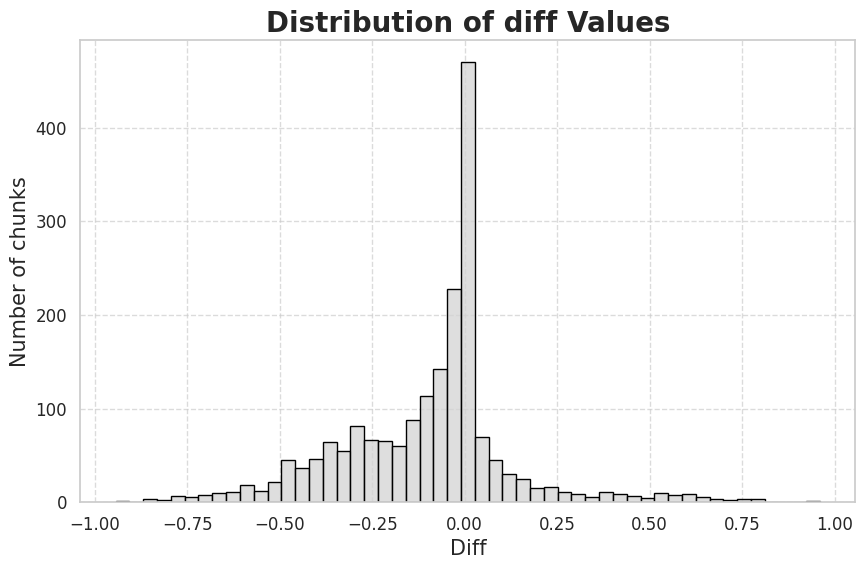

In [12]:
# close to 1 = sbcr is better
# close to -1 = mergegen is better
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(10, 6))
ax = sns.histplot(df_results_clean['diff'],color='lightgray', edgecolor='black')

plt.title('Distribution of diff Values', fontsize=20, weight='bold')
plt.xlabel('Diff', fontsize=15)
plt.ylabel('Number of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)

# plt.savefig('RQ4_histogram_z_distribution.png', dpi=300, bbox_inches='tight')

plt.show()

In [13]:
df_stats = pd.read_csv(DATASET2_STATS)
df = df_results_clean.merge(df_stats, on='chunk_id')
df['diff_chunk_solution'] = df['chunk_size_char'] - df['solution_size_char']
df['chunk_diff_lines'] = df['v1_size'] - df['v2_size']
df['v1_size_rel'] = df['v1_size']/(df['v1_size'] + df['v2_size'])
df['v2_size_rel'] = df['v2_size']/(df['v1_size'] + df['v2_size'])
df['chunk_diff_lines_rel'] = df['v1_size_rel'] - df['v2_size_rel']
df['chunk_diff_char'] = df['v1_size_char'] - df['v2_size_char']
df['v1_size_char_rel'] = df['v1_size_char']/(df['v1_size_char'] + df['v2_size_char'])
df['v2_size_char_rel'] = df['v2_size_char']/(df['v1_size_char'] + df['v2_size_char'])
df['chunk_diff_char_rel'] = df['v1_size_char_rel'] - df['v2_size_char_rel']
df

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff,chunk_size,...,resolution_parents_sim,diff_chunk_solution,chunk_diff_lines,v1_size_rel,v2_size_rel,chunk_diff_lines_rel,chunk_diff_char,v1_size_char_rel,v2_size_char_rel,chunk_diff_char_rel
0,247633-11,0.772002,0.413502,0.195323,37554,1.000000,0.098506,0.589247,-0.586498,6,...,0.589191,191,0,0.500000,0.500000,0.000000,-23,0.452282,0.547718,-0.095436
1,218430-3,0.947421,1.000000,0.825038,59863,1.000000,0.190504,0.939097,0.000000,5,...,0.946990,82,-1,0.400000,0.600000,-0.200000,9,0.525714,0.474286,0.051429
2,64045-1,0.979891,0.981432,2.291695,5235,1.000000,0.299400,0.979356,-0.018568,5,...,0.979885,187,-1,0.400000,0.600000,-0.200000,-15,0.479893,0.520107,-0.040214
3,276497-1,0.844135,1.000000,0.300525,28978,0.984456,0.360160,0.838726,0.015544,8,...,0.843996,111,-4,0.250000,0.750000,-0.500000,-91,0.360000,0.640000,-0.280000
4,228270-4,0.741226,0.818408,0.874901,19428,1.000000,1.350036,0.723848,-0.181592,18,...,0.733408,93,0,0.500000,0.500000,0.000000,-111,0.402116,0.597884,-0.195767
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1962,258478-4,0.978495,1.000000,1.557349,35832,1.000000,0.380552,0.977431,0.000000,5,...,0.978444,232,-1,0.400000,0.600000,-0.200000,2,0.502155,0.497845,0.004310
1963,167370-1,0.688285,0.506004,10.421561,17374,0.711382,1.345684,0.604090,-0.205378,49,...,0.672670,1744,29,0.795918,0.204082,0.591837,1367,0.772419,0.227581,0.544839
1964,91740-2,0.795016,0.793651,2.451555,55023,0.696629,0.246882,0.788434,0.097022,4,...,0.719672,71,0,0.500000,0.500000,0.000000,77,0.701571,0.298429,0.403141
1965,136898-33,0.968289,0.991394,0.611825,39157,1.000000,0.545362,0.982399,-0.008606,8,...,0.968260,304,0,0.500000,0.500000,0.000000,28,0.523411,0.476589,0.046823


In [14]:
# cases where mergeGen is better
print(len(df[df['diff'] < 0]))
df.sort_values('diff').to_csv(MERGEGEN_BETTER)
df.sort_values('diff').head(20)


1268


,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff,chunk_size,...,resolution_parents_sim,diff_chunk_solution,chunk_diff_lines,v1_size_rel,v2_size_rel,chunk_diff_lines_rel,chunk_diff_char,v1_size_char_rel,v2_size_char_rel,chunk_diff_char_rel
1630,271520-1,0.508981,0.055845,9.890369,41244,1.000000,0.199575,0.518271,-0.944155,38,...,0.518457,3345,-36,0.026316,0.973684,-0.947368,-3259,0.025895,0.974105,-0.948211
352,273431-10,0.498551,0.142077,0.151813,46454,1.000000,0.349795,0.073770,-0.857923,10,...,0.079787,158,-10,0.000000,1.000000,-1.000000,-173,0.000000,1.000000,-1.000000
1689,146018-2,0.571983,0.151934,0.431515,10905,1.000000,0.963618,0.591751,-0.848066,19,...,0.570411,74,-17,0.052632,0.947368,-0.894737,-633,0.075168,0.924832,-0.849664
198,170349-1,0.575104,0.162991,1.093204,1713,1.000000,0.999941,0.529438,-0.837009,26,...,0.530216,115,20,0.884615,0.115385,0.769231,904,0.919295,0.080705,0.838590
781,96520-2,0.582683,0.175331,0.402613,45941,1.000000,0.955035,0.640199,-0.824669,18,...,0.587019,84,-16,0.055556,0.944444,-0.888889,-807,0.088685,0.911315,-0.822630
875,127331-12,0.588115,0.179817,0.201282,11822,1.000000,0.543368,0.608249,-0.820183,12,...,0.589396,50,-10,0.083333,0.916667,-0.833333,-447,0.091408,0.908592,-0.817185
528,125392-1,0.728471,0.209632,0.352553,53733,1.000000,0.825823,0.381409,-0.790368,10,...,0.382764,380,4,0.700000,0.300000,0.400000,222,0.765550,0.234450,0.531100
1459,119750-1,0.672389,0.212766,0.285829,14352,1.000000,0.115399,0.397018,-0.787234,9,...,0.398326,258,3,0.666667,0.333333,0.333333,164,0.788732,0.211268,0.577465
1883,125017-1,0.648088,0.222222,0.335260,24890,1.000000,0.197215,0.505560,-0.777778,9,...,0.506370,361,5,0.777778,0.222222,0.555556,262,0.821078,0.178922,0.642157
1666,64538-1,0.497947,0.225092,0.398460,26147,1.000000,0.125199,0.124153,-0.774908,21,...,0.112523,427,-21,0.000000,1.000000,-1.000000,-489,0.000000,1.000000,-1.000000


In [15]:
# cases where sbcr is better
print(len(df[df['diff'] > 0]))
df.sort_values('diff', ascending=False).to_csv(SBCR_BETTER)
df.sort_values('diff', ascending=False).head(20)

430


,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff,chunk_size,...,resolution_parents_sim,diff_chunk_solution,chunk_diff_lines,v1_size_rel,v2_size_rel,chunk_diff_lines_rel,chunk_diff_char,v1_size_char_rel,v2_size_char_rel,chunk_diff_char_rel
1603,210567-1,0.496888,0.961123,0.472502,53902,0.000000,0.575490,0.500000,0.961123,15,...,0.483493,31,-15,0.000000,1.000000,-1.000000,-485,0.000000,1.000000,-1.000000
488,56194-1,0.869904,1.000000,0.455784,8953,0.191837,1.343968,0.220722,0.808163,7,...,0.849816,194,-3,0.285714,0.714286,-0.428571,-149,0.367201,0.632799,-0.265597
1247,247229-2,0.506498,0.959817,31.608708,57095,0.157301,1.322153,0.223663,0.802516,191,...,0.524403,154,179,0.968586,0.031414,0.937173,7894,0.973261,0.026739,0.946523
758,110160-3,0.497329,0.800830,4.824927,17980,0.000000,1.332607,0.500000,0.800830,102,...,0.398256,700,-102,0.000000,1.000000,-1.000000,-2070,0.000000,1.000000,-1.000000
682,150763-1,0.880208,0.868120,186.743766,26969,0.076561,1.328693,0.077741,0.791559,826,...,0.983690,18987,8,0.504843,0.495157,0.009685,533,0.506911,0.493089,0.013823
329,142483-1,0.541449,0.965854,9.862402,7038,0.193029,1.325029,0.356384,0.772824,68,...,0.527637,2170,64,0.970588,0.029412,0.941176,2075,0.955643,0.044357,0.911287
1117,123077-3,0.484786,0.963417,20.882007,15718,0.215044,1.342059,0.148046,0.748373,100,...,0.487450,272,98,0.990000,0.010000,0.980000,5451,0.999817,0.000183,0.999633
520,80473-9,0.572010,0.900651,35.821788,24971,0.154771,1.329739,0.395825,0.745880,278,...,0.596598,2741,162,0.791367,0.208633,0.582734,9095,0.851185,0.148815,0.702371
180,94502-2,0.589536,0.981013,1.101367,35466,0.247126,0.758430,0.607345,0.733886,19,...,0.590622,60,-17,0.052632,0.947368,-0.894737,-428,0.099251,0.900749,-0.801498
369,223512-1,0.504654,0.722892,0.119653,35700,0.000000,0.308375,0.500000,0.722892,6,...,0.374389,70,4,0.833333,0.166667,0.666667,160,0.993827,0.006173,0.987654


In [16]:
df_mergegen = df[df['diff'] < 0]
df_sbcr = df[df['diff'] > 0]

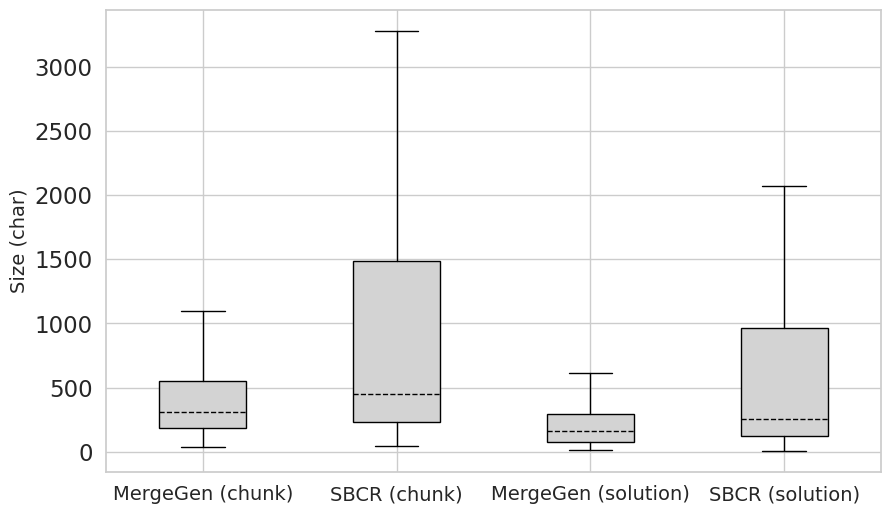

In [17]:
# Create a boxplot
plt.figure(figsize=(10, 6))  # Set the figure size
plt.boxplot([df_mergegen['chunk_size_char'], df_sbcr['chunk_size_char'], df_mergegen['solution_size_char'], df_sbcr['solution_size_char']], 
            patch_artist=True,  # To fill the box with color
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  # Color of the median line
            boxprops=dict(facecolor='lightgray', color='black'),  # Color of the box
            whiskerprops=dict(color='black'),  # Color of the whiskers
            capprops=dict(color='black'),  # Color of the caps
            showfliers=False)  # Properties of the outliers

# Customize labels and title
# plt.xlabel('Your X Label')
plt.ylabel('Size (char)', fontsize=14)
plt.xticks([1, 2, 3, 4], ['MergeGen (chunk)', 'SBCR (chunk)', 'MergeGen (solution)', 'SBCR (solution)'], fontsize=14)
# plt.title('Similarity between random candidates and parents \n using each aggregation function', fontsize=16)

# Save or show the plot
# plt.savefig('RQ3_boxplots.png', dpi=300)  # Save the plot as a PNG file with higher resolution
plt.show()  # Show the plot

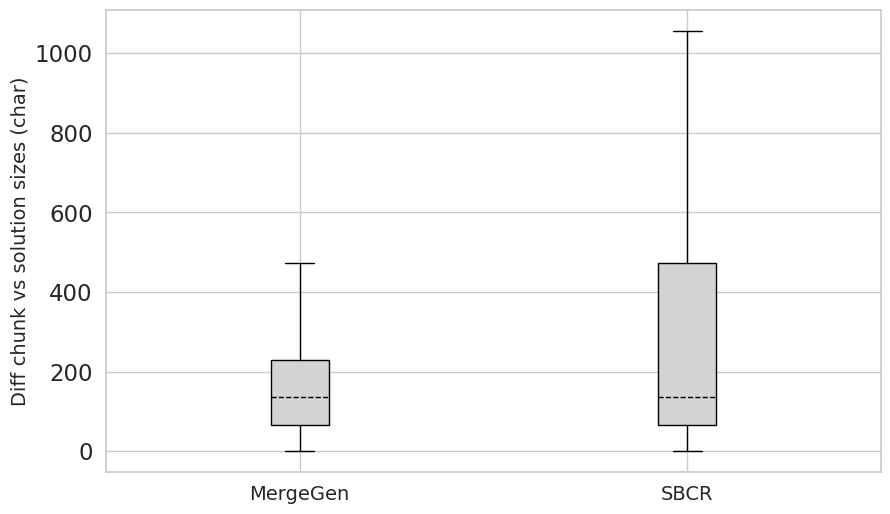

In [18]:
plt.figure(figsize=(10, 6))  # Set the figure size
plt.boxplot([df_mergegen['diff_chunk_solution'], df_sbcr['diff_chunk_solution']], 
            patch_artist=True,  # To fill the box with color
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  # Color of the median line
            boxprops=dict(facecolor='lightgray', color='black'),  # Color of the box
            whiskerprops=dict(color='black'),  # Color of the whiskers
            capprops=dict(color='black'),  # Color of the caps
            showfliers=False)  # Properties of the outliers

plt.ylabel('Diff chunk vs solution sizes (char)', fontsize=14)
plt.xticks([1, 2], ['MergeGen', 'SBCR'], fontsize=14)

plt.show()  # Show the plot

In [19]:
print(df_mergegen[['fitness_sbcr','diff_chunk_solution']].describe())
print(df_sbcr[['fitness_sbcr','diff_chunk_solution']].describe())
            

       fitness_sbcr  diff_chunk_solution
count   1268.000000          1268.000000
mean       0.749414           209.690063
std        0.157449           332.767180
min        0.469684             1.000000
25%        0.632288            67.000000
50%        0.772854           135.000000
75%        0.878834           230.250000
max        0.991234          6635.000000
       fitness_sbcr  diff_chunk_solution
count    430.000000           430.000000
mean       0.756067           862.046512
std        0.147200          2345.627116
min        0.363980             1.000000
25%        0.669986            65.250000
50%        0.776779           136.500000
75%        0.869864           473.500000
max        0.990039         19301.000000


In [20]:
df['fitness_to_solution_diff'] = df['mergegen_parents_sim'] - df['fitness_sbcr']

In [21]:
df[(df['diff'] < 0) & (df['mergegen_parents_sim'] > df['fitness_sbcr'])].sort_values('fitness_to_solution_diff', ascending=False)

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim,diff,chunk_size,...,diff_chunk_solution,chunk_diff_lines,v1_size_rel,v2_size_rel,chunk_diff_lines_rel,chunk_diff_char,v1_size_char_rel,v2_size_char_rel,chunk_diff_char_rel,fitness_to_solution_diff
365,259897-2,0.787450,0.585987,0.702508,38261,0.994536,0.213398,0.908559,-0.408548,7,...,100,-5,0.142857,0.857143,-0.714286,-137,0.287926,0.712074,-0.424149,0.121109
691,271732-3,0.882385,0.986054,1.702724,20748,1.000000,0.683855,0.957122,-0.013946,14,...,398,6,0.714286,0.285714,0.428571,205,0.601787,0.398213,0.203575,0.074737
1529,236759-5,0.833669,0.759398,0.094537,22374,1.000000,0.146591,0.906354,-0.240602,5,...,68,-1,0.400000,0.600000,-0.200000,-12,0.470000,0.530000,-0.060000,0.072685
1939,261590-4,0.773959,0.553435,1.523362,32745,1.000000,0.585031,0.844441,-0.446565,11,...,145,-9,0.090909,0.909091,-0.818182,-233,0.278095,0.721905,-0.443810,0.070482
1366,283097-4,0.816825,0.893782,1.813408,48187,1.000000,0.536310,0.881974,-0.106218,12,...,196,-6,0.250000,0.750000,-0.500000,-181,0.355200,0.644800,-0.289600,0.065149
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499,278803-2,0.889475,0.927022,0.547329,20222,0.976744,0.388684,0.889646,-0.049722,9,...,200,-1,0.444444,0.555556,-0.111111,-19,0.478652,0.521348,-0.042697,0.000171
822,69463-3,0.991234,0.984848,2.442503,13943,1.000000,0.267079,0.991379,-0.015152,5,...,198,-1,0.400000,0.600000,-0.200000,5,0.506266,0.493734,0.012531,0.000145
1493,256742-3,0.887880,0.771930,2.616292,60135,1.000000,0.150712,0.887963,-0.228070,4,...,126,-2,0.250000,0.750000,-0.500000,-41,0.411255,0.588745,-0.177489,0.000083
1010,216520-1,0.727248,0.892019,0.104857,4204,0.938776,0.146917,0.727266,-0.046757,8,...,32,4,0.750000,0.250000,0.500000,66,0.722973,0.277027,0.445946,0.000018


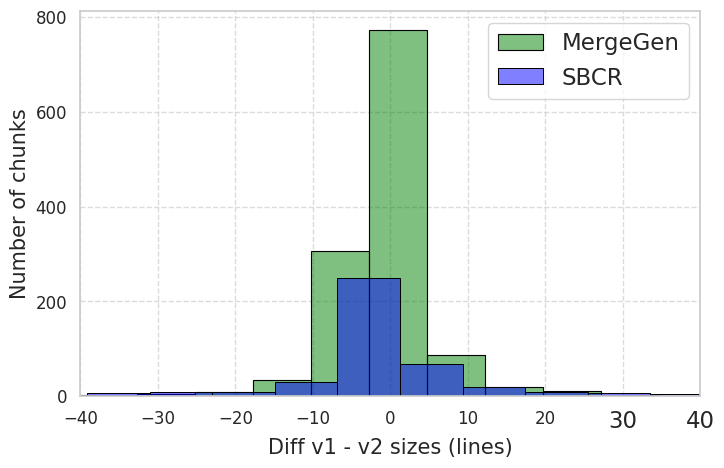

In [22]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_lines'], bins=50, color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_lines'],bins=50, color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (lines)', fontsize=15)
plt.ylabel('Number of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(-40,40)
plt.legend()
plt.show()

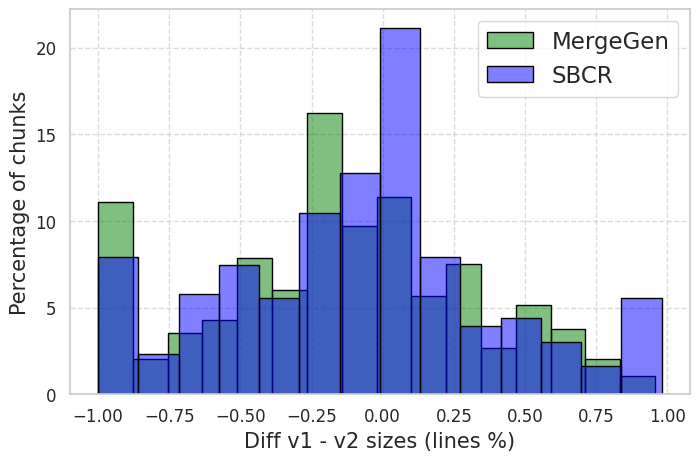

In [23]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_lines_rel'], stat='percent',color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_lines_rel'], stat='percent', color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (lines %)', fontsize=15)
plt.ylabel('Percentage of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
# plt.xlim(-40,40)
plt.legend()
plt.show()

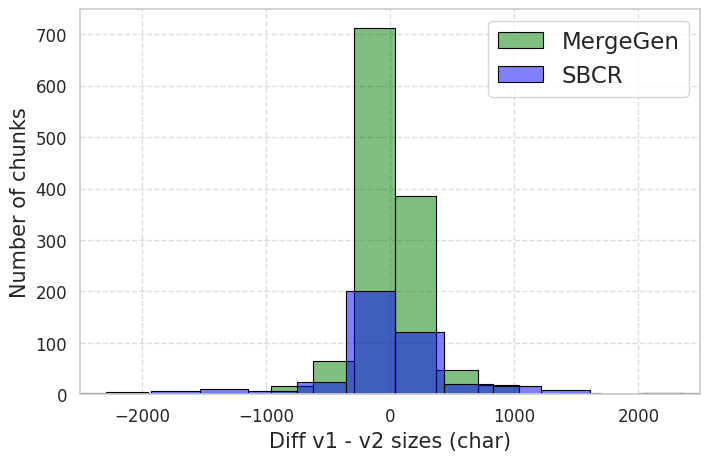

In [24]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_char'], bins=50, color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_char'],bins=50, color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (char)', fontsize=15)
plt.ylabel('Number of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(-2500,2500)
plt.legend()
plt.show()

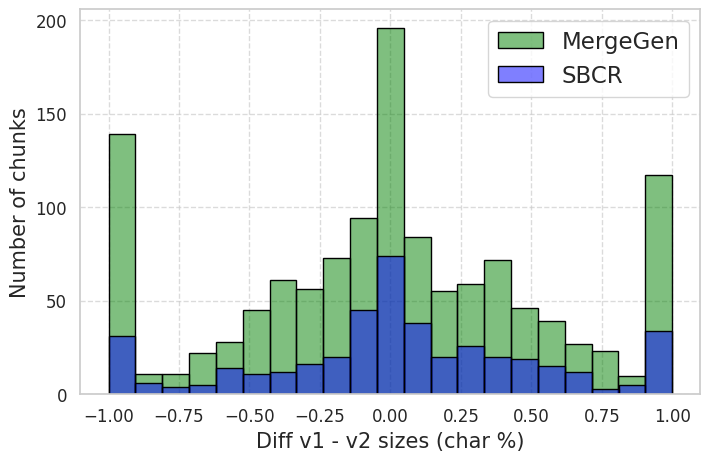

In [25]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_char_rel'], bins=21, color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_char_rel'], bins=21, color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (char %)', fontsize=15)
plt.ylabel('Number of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
# plt.xlim(-40,40)
plt.legend()
plt.show()

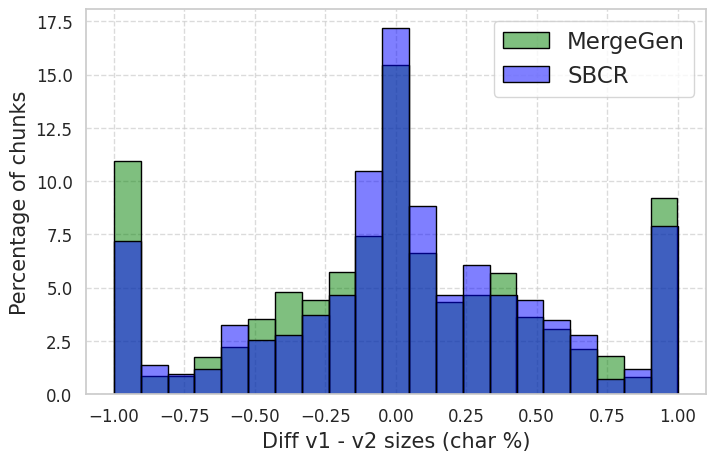

In [26]:
sns.set(style="whitegrid")
sns.set_context("notebook", font_scale=1.5)

plt.figure(figsize=(8, 5))
ax = sns.histplot(df_mergegen['chunk_diff_char_rel'], bins=21, stat='percent',color='green', label="MergeGen", edgecolor='black', alpha=0.5)
ax = sns.histplot(df_sbcr['chunk_diff_char_rel'], bins=21, stat='percent', color='blue', label="SBCR", edgecolor='black', alpha=0.5)

plt.xlabel('Diff v1 - v2 sizes (char %)', fontsize=15)
plt.ylabel('Percentage of chunks', fontsize=15)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
# plt.xlim(-40,40)
plt.legend()
plt.show()